# Clima y demanda del subte de Buenos Aires (2018–2021): reproducción en Colab

Trabajo Final Integrador, Metodología de la Investigación, Grupo 36.

Ejecutá las celdas en orden con *Entorno de ejecución → Ejecutar todas*. No hace falta cuenta de GitHub ni de Google para los datos. La corrida completa tarda unos 10 a 15 minutos; el paso más largo es el script 03, que procesa unos 25 millones de filas.

Las versiones de Colab difieren de las originales (Python 3.8, pandas 2.0.3, numpy 1.24); pueden aparecer diferencias numéricas menores, que la celda 6 permite ver.

In [1]:
# 1. Clonar el repositorio (público, sin credenciales)
REPO_URL = "https://github.com/leonnf/clima-demanda-subte-bsas.git"
RAIZ = "/content/clima-demanda-subte-bsas"

import os
if not os.path.exists(RAIZ):
    !git clone -q {REPO_URL} {RAIZ}
%cd {RAIZ}
!git log --oneline -1

/content/clima-demanda-subte-bsas
4ecdf9f (HEAD -> main, origin/main, origin/HEAD) Corrige notebook de Colab y actualiza los README con las formas de ejecución


In [2]:
# 2. Dependencias
# Colab ya trae numpy, scipy, statsmodels, scikit-learn, matplotlib y pyarrow.
# Solo aseguramos pandas 2.x (con pandas 3 cambian levemente los días atípicos)
# y las librerías que no vienen preinstaladas. No se fija numpy: numpy 1.x no tiene
# versión compilada para el Python de Colab (3.13) y pip intentaría compilarlo.
!pip -q install "pandas>=2.2,<3" holidays gdown statsmodels scikit-learn pyarrow

import sys, numpy, pandas, sklearn, statsmodels
print("Python", sys.version.split()[0], "| numpy", numpy.__version__, "| pandas", pandas.__version__,
      "| scikit-learn", sklearn.__version__, "| statsmodels", statsmodels.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | statsmodels 0.15.0


In [3]:
# 3. Datos crudos (dsets/). El clima y la demanda diaria ya vienen en recursos/.
# Por defecto se descarga dsets.zip del Drive del grupo (público, solo lectura).
# Alternativa: FUENTE = "catedra" baja la carpeta original de la cátedra.
FUENTE = "espejo_grupo"
ID_ZIP_GRUPO = "1Oe0TMeqHbQueOMjrGGuSEbe4SOoa42Bg"
ID_CARPETA_CATEDRA = "1N_upx66kxNa6MqUD40SsvJqioQLJ8jdm"

import os, glob, shutil
if os.path.exists("dsets/historico_2019.csv"):
    print("dsets/ ya está presente, no se descarga.")
elif FUENTE == "espejo_grupo":
    !gdown {ID_ZIP_GRUPO} -O dsets.zip
    !unzip -q -o dsets.zip && rm -f dsets.zip
    # Si el zip no traía la carpeta dsets/, mover los archivos sueltos a dsets/
    if not os.path.exists("dsets/historico_2019.csv"):
        os.makedirs("dsets", exist_ok=True)
        for f in glob.glob("*.csv") + glob.glob("*.xlsx"):
            shutil.move(f, "dsets/")
else:
    !gdown --folder {ID_CARPETA_CATEDRA} -O dsets

!ls -lh dsets/

Downloading...
From (original): https://drive.google.com/uc?id=1Oe0TMeqHbQueOMjrGGuSEbe4SOoa42Bg
From (redirected): https://drive.google.com/uc?id=1Oe0TMeqHbQueOMjrGGuSEbe4SOoa42Bg&confirm=t&uuid=5c16d744-4e37-4308-ba51-d7c40848a988
To: /content/clima-demanda-subte-bsas/dsets.zip
100% 332M/332M [00:07<00:00, 42.7MB/s]
total 3.4G
-rw-rw-r-- 1 root root  30M Aug 25  2025 BaseUnificadaEstaciones.csv
-rw-rw-r-- 1 root root 5.1K Aug 25  2025 estaciones-accesibles.csv
-rw-rw-r-- 1 root root 1.1G Oct  9 22:28 historico_2018.csv
-rw-rw-r-- 1 root root 1.2G Sep  4 02:13 historico_2019.csv
-rw-rw-r-- 1 root root 444M Aug 25  2025 historico_2020.csv
-rw-rw-r-- 1 root root 658M Sep  4 02:11 historico_2021.csv
-rw-rw-r-- 1 root root  21K Aug 25  2025 lineas-de-subte.csv
-rw-rw-r-- 1 root root 6.0K Aug 25  2025 registro-historico-del-precio-del-boleto.csv
-rw-rw-r-- 1 root root  11K Aug 25  2025 registro-historico-del-precio-del-boleto.xlsx
-rw-rw-r-- 1 root root  828 Aug 25  2025 viajes_anual.csv


In [4]:
# 4. Verificar los datos contra el manifiesto (SHA-256)
# Los archivos de dsets/ deben dar OK. Los Parquet de recursos/ aparecen como FALTA
# hasta que se ejecutan los scripts 02 y 03 (celda 5): es lo esperado.
!python descargar_datos.py --solo-verificar

Solo verificación: no se descarga nada.
DATA_DIR = /content/clima-demanda-subte-bsas
estado     archivo
OK         dsets/BaseUnificadaEstaciones.csv
OK         dsets/estaciones-accesibles.csv
OK         dsets/historico_2018.csv
OK         dsets/historico_2019.csv
OK         dsets/historico_2020.csv
OK         dsets/historico_2021.csv
OK         dsets/lineas-de-subte.csv
OK         dsets/registro-historico-del-precio-del-boleto.csv
OK         dsets/registro-historico-del-precio-del-boleto.xlsx
OK         dsets/viajes_anual.csv
OK         recursos/00_extraccion_y_curacion_datos_climaticos.ipynb
OK         recursos/00_extraccion_y_curacion_datos_climaticos.pdf
OK         recursos/00_extraccion_y_curacion_datos_climaticos_SL.ipynb
OK         recursos/01_analisis_precipitaciones_y_demanda_subte.ipynb
OK         recursos/01_analisis_precipitaciones_y_demanda_subte.pdf
OK         recursos/63cf6db99b9e0b24ffdff2aa5ff741f20f7f135a.png
FALTA      recursos/base_analitica.parquet
OK         recurs

In [5]:
# 5. Ejecutar el pipeline completo, en orden
import subprocess, sys, time
SCRIPTS = [
    "02_base_analitica.py",
    "03_molinetes_2018_2019.py",
    "03b_verificacion_2020_2021.py",
    "03c_explicacion_diferencias.py",
    "04_eda.py",
    "05_hipotesis.py",
    "06_segmentacion_H3.py",
    "07_modelo_predictivo.py",
    "09_figuras.py",
]
total = time.time()
for s in SCRIPTS:
    t = time.time()
    r = subprocess.run([sys.executable, f"Ultima entrega/notebooks/{s}"], capture_output=True, text=True)
    print(f"{s:34s} rc={r.returncode}  {time.time() - t:6.0f} s")
    if r.returncode != 0:
        print(r.stdout[-1500:]); print(r.stderr[-3000:])
        raise SystemExit(f"Falló {s}")
print(f"Total: {(time.time() - total) / 60:.1f} min")

02_base_analitica.py               rc=0       7 s
03_molinetes_2018_2019.py          rc=0     212 s
03b_verificacion_2020_2021.py      rc=0     234 s
03c_explicacion_diferencias.py     rc=0       1 s
04_eda.py                          rc=0       1 s
05_hipotesis.py                    rc=0      10 s
06_segmentacion_H3.py              rc=0      13 s
07_modelo_predictivo.py            rc=0      26 s
09_figuras.py                      rc=0       9 s
Total: 8.5 min


In [6]:
# 6. Comparar con los resultados publicados en el repositorio
# git diff muestra qué tablas cambiaron respecto de la versión del informe.
# Con otras versiones de pandas pueden variar levemente los días atípicos (ver README).
!git diff --stat -- "Ultima entrega/resultados/tablas"

import pandas as pd
pd.set_option("display.width", 200)
T = "Ultima entrega/resultados/tablas/"
for nombre in ["t05_especificaciones", "t05_h2_contraste", "t06_kmeans_diagnostico", "t07_metricas"]:
    print(f"\n=== {nombre} ===")
    display(pd.read_csv(T + nombre + ".csv"))

 .../resultados/tablas/t02_dias_atipicos.csv        |  72 ++++-----
 .../tablas/t04_correlacion_temp_demanda.csv        |   6 +-
 .../resultados/tablas/t04_demanda_por_tipo_dia.csv |   4 +-
 .../resultados/tablas/t05_especificaciones.csv     |  10 +-
 .../tablas/t05_h1_sensibilidad_termica.csv         |   2 +-
 .../resultados/tablas/t05_robustez_tarifa.csv      |   4 +-
 Ultima entrega/resultados/tablas/t05_temp_bins.csv |  10 +-
 Ultima entrega/resultados/tablas/t06_clusters.csv  |   8 +-
 .../resultados/tablas/t06_estaciones_excluidas.csv |   4 +-
 .../resultados/tablas/t06_kmeans_diagnostico.csv   |  10 +-
 .../resultados/tablas/t06_pca_varianza.csv         |   6 +-
 .../tablas/t06_perfil_vs_csv_por_estacion.csv      | 170 ++++++++++-----------
 .../tablas/t06_perfil_vs_csv_resumen.csv           |   2 +-
 .../tablas/t07_importancia_permutacion.csv         |  28 ++--
 Ultima entrega/resultados/tablas/t07_metricas.csv  |  10 +-
 15 files changed, 174 insertions(+), 172 deletions(-)

=

,modelo,n,r2,r2_ajustado,beta_temp,ic_temp_bajo,ic_temp_alto,p_temp_hac,t_temp_ols,p_temp_ols,beta_lluvia,p_lluvia_hac,ic_lluvia_bajo,ic_lluvia_alto,vif_temp_max,vif_lluvia,durbin_watson,bp_pvalor
0,M0,1425,0.359527,0.357723,-7578.186072,-15915.046909,758.674765,0.074780,-3.785177,0.000160,22481.943187,0.497366,-42486.370820,87450.257194,1.071499,1.006888,0.591274,0.0
1,M1,1425,0.807190,0.798856,-1178.985881,-6154.697194,3796.725432,0.642133,-0.532517,0.594455,-5578.191550,0.764909,-42163.803037,31007.419936,4.184084,1.057703,1.382264,0.0
2,M2,1425,0.711911,0.699458,0.001217,-0.012439,0.014874,0.861211,0.160446,0.872554,0.032801,0.529200,-0.069435,0.135037,4.184084,1.057703,1.553734,0.0
3,M3,1425,0.807315,0.798986,-1041.634244,-6015.272772,3932.004285,0.681253,-0.470685,0.637941,-732.046631,0.324358,-2188.647723,724.554462,4.183123,NaN,1.381062,0.0
4,M4,1425,0.775943,0.766429,1153.183593,-4307.919790,6614.286975,0.678764,0.484573,0.628057,-9994.028288,0.619003,-49411.379630,29423.323054,4.163097,1.057431,1.313714,0.0
5,M5,727,0.931948,0.928707,-3901.826880,-6998.717109,-804.936652,0.013610,-2.487469,0.013100,-18944.121664,0.181127,-46729.623242,8841.379914,4.040943,1.072451,1.708785,0.0



=== t05_h2_contraste ===


,analisis,n_seco,n_lluvia,media_seco,media_lluvia,diferencia,t_welch,p_welch_unilateral,p_welch_bilateral,ic95_dif_bajo,ic95_dif_alto,mannwhitney_U,p_mannwhitney_unilateral,cohen_d,d_ic95_bajo,d_ic95_alto
0,demanda cruda (H2 principal),244,70,1.269706e+06,1.224068e+06,-45637.33911,-2.420945,0.991379,0.017242,-83027.030626,-8247.647594,5995.5,0.999928,-0.350524,-0.637637,-0.075024



=== t06_kmeans_diagnostico ===


,k,inercia,silueta,iteraciones
0,2,0.3014,0.4896,7
1,3,0.1734,0.4784,3
2,4,0.1091,0.4957,3
3,5,0.0944,0.3826,5
4,6,0.0826,0.3889,8



=== t07_metricas ===


,modelo,n_test_2019,rmse_2019,mae_2019,mape_2019,r2_2019,rmse_2018,delta_rmse_vs_modelo2
0,1_ingenuo_semana_anterior,359,276098.6805,124829.9582,28.2405,0.5865,357038.6457,142575.7019
1,2_regresion_calendario,362,133522.9786,84011.9109,18.3982,0.9032,147071.7022,0.0000
2,3_regresion_calendario_clima,362,130998.3421,82887.7920,18.7461,0.9068,135366.1844,-2524.6365
3,4_random_forest,362,103540.4389,71394.7388,21.6218,0.9418,116673.9429,-29982.5397
4,5_hist_gradient_boosting,362,126393.4161,81417.0829,20.1769,0.9132,113671.4385,-7129.5625


fig01_serie_diaria_fases_atipicos.png


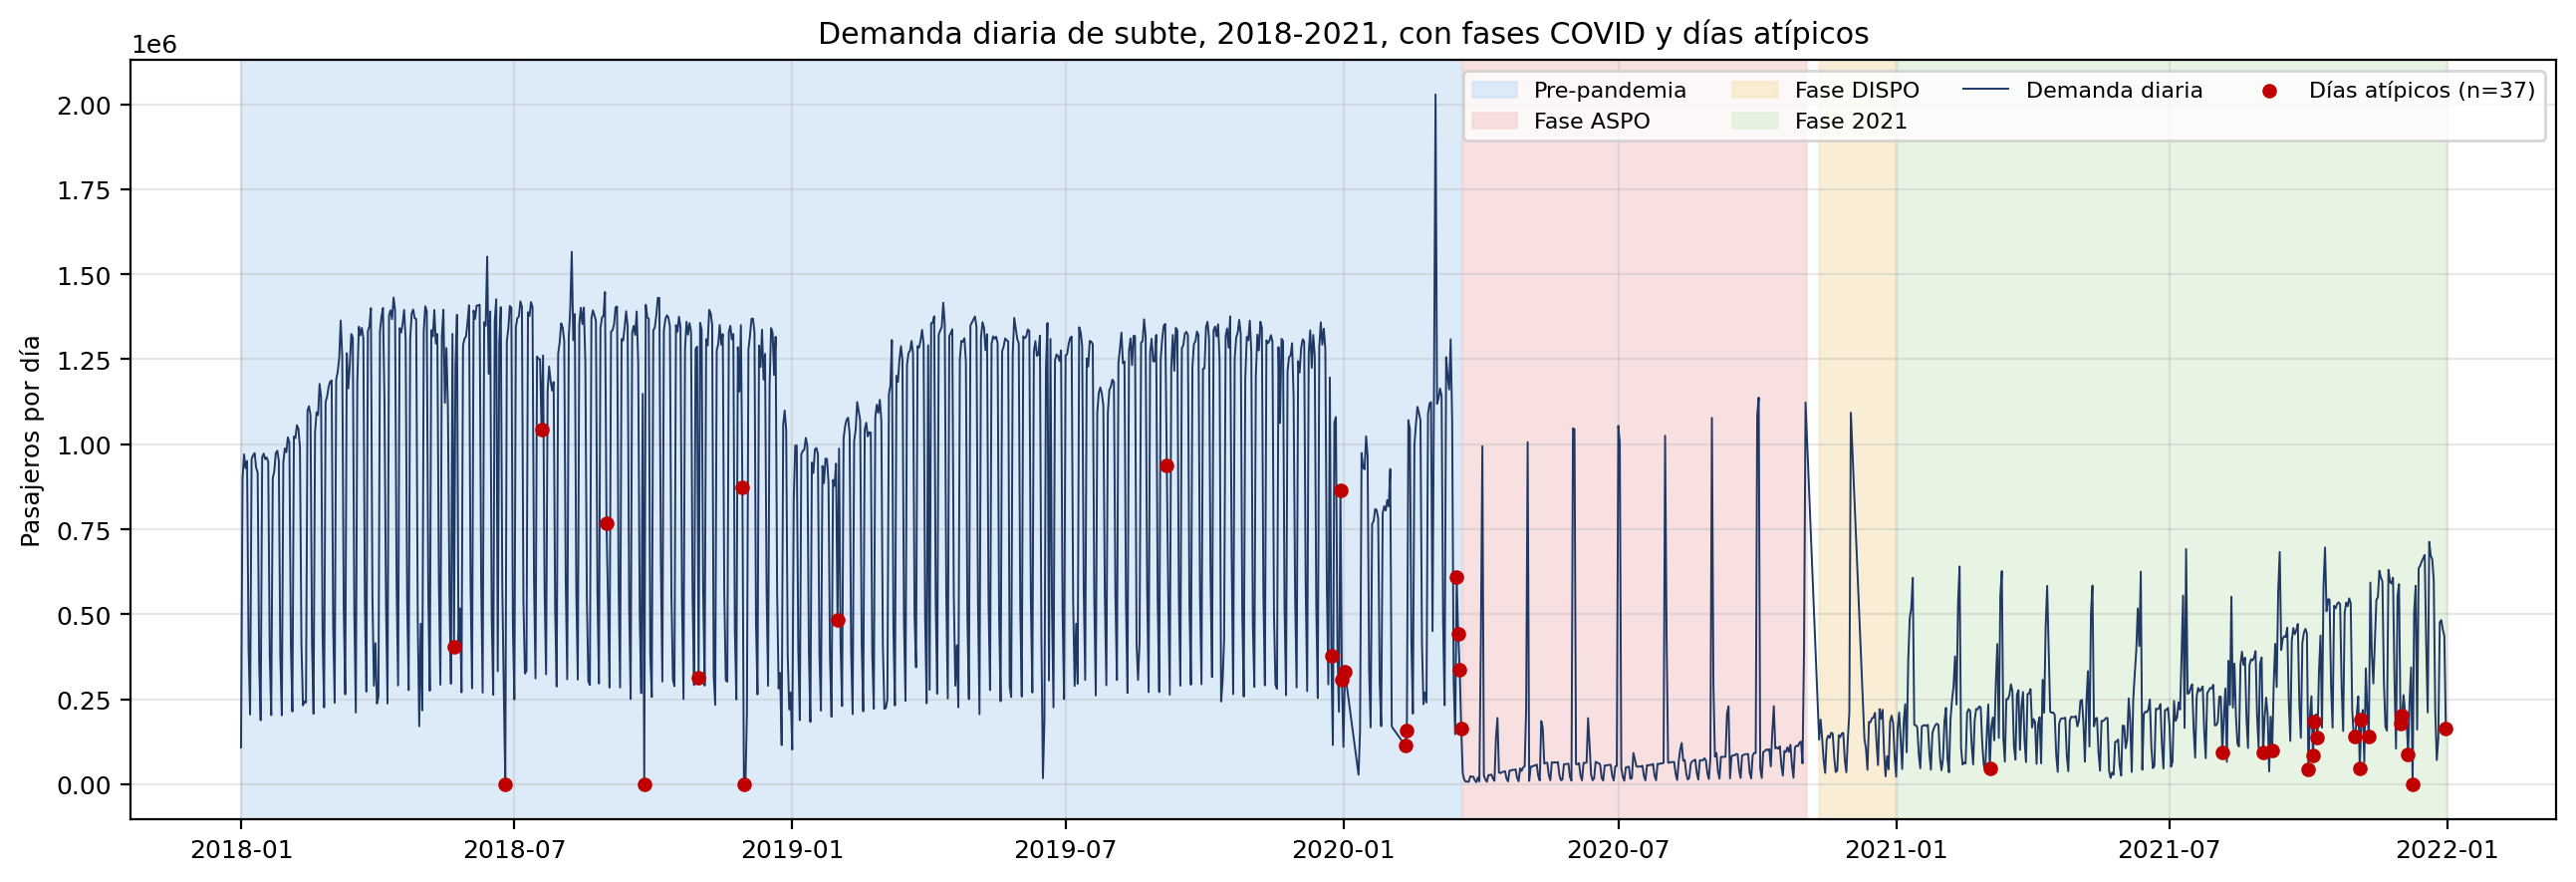

fig05_boxplots_h2.png


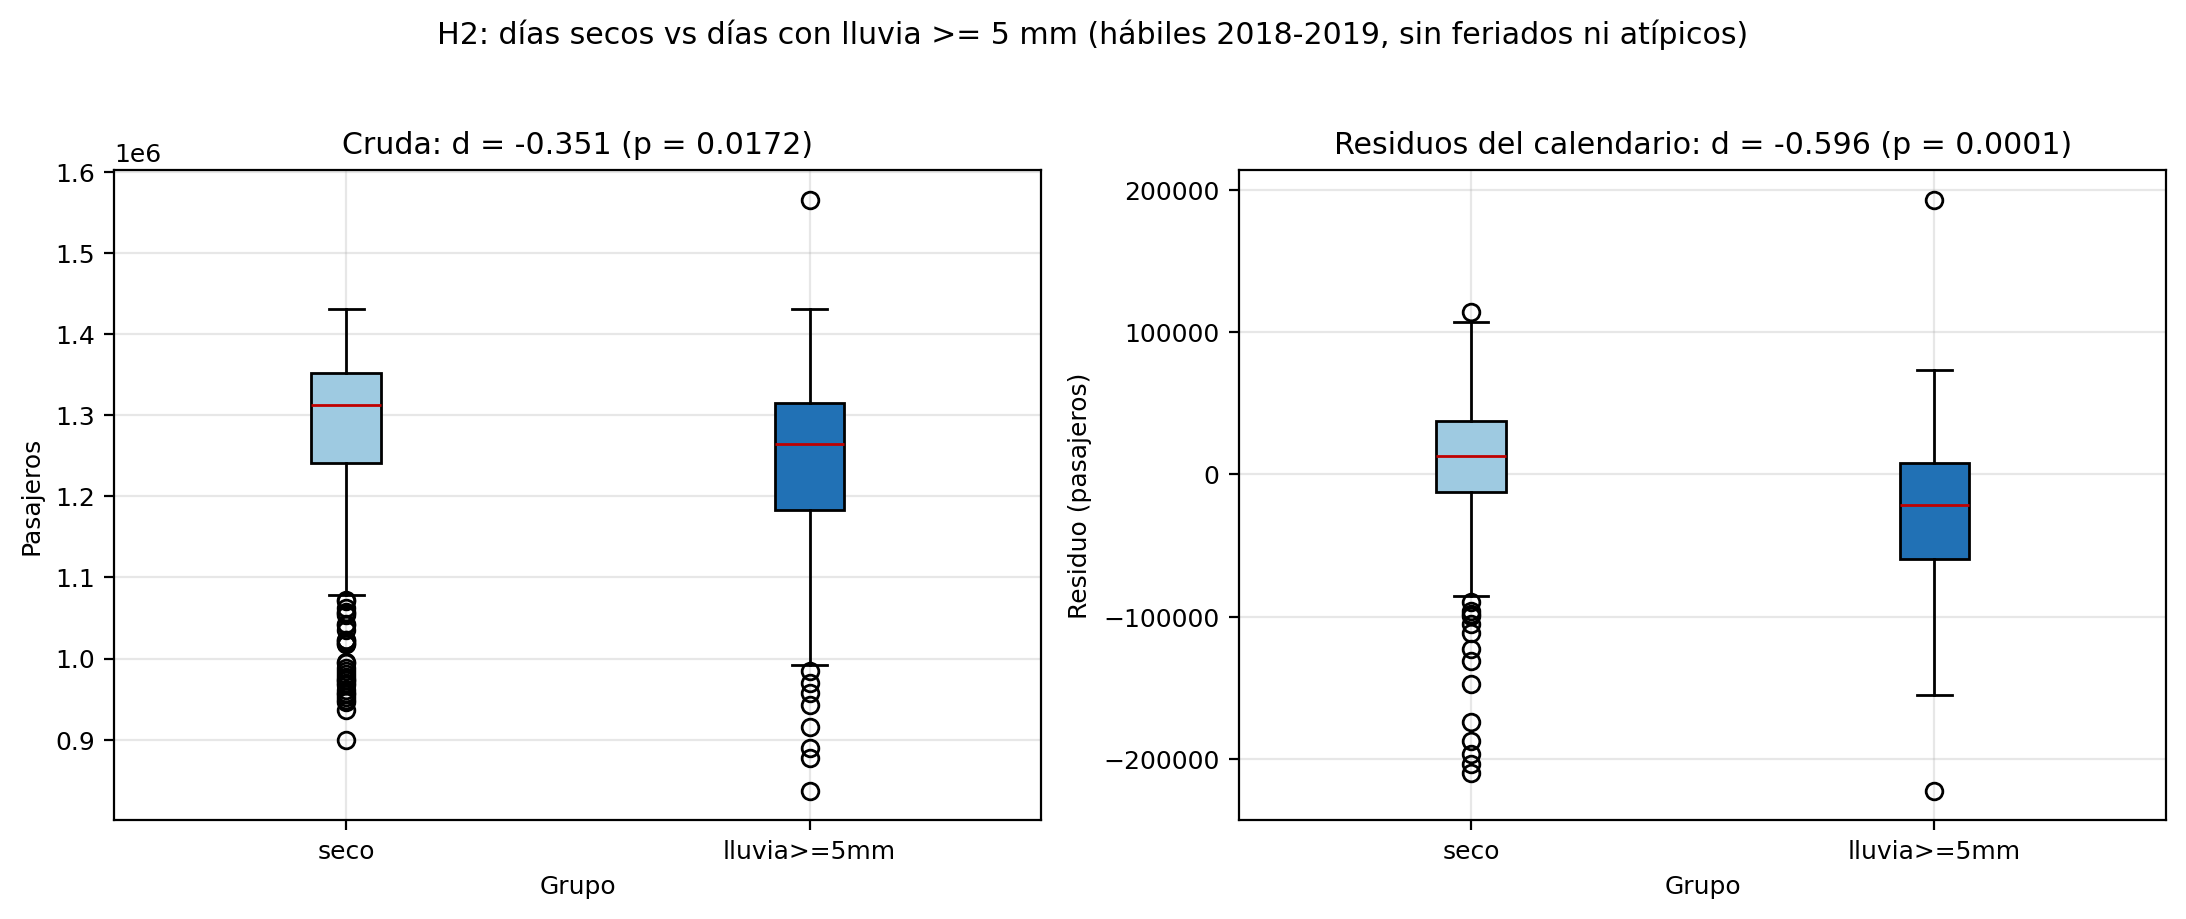

fig06_forest_plot_especificaciones.png


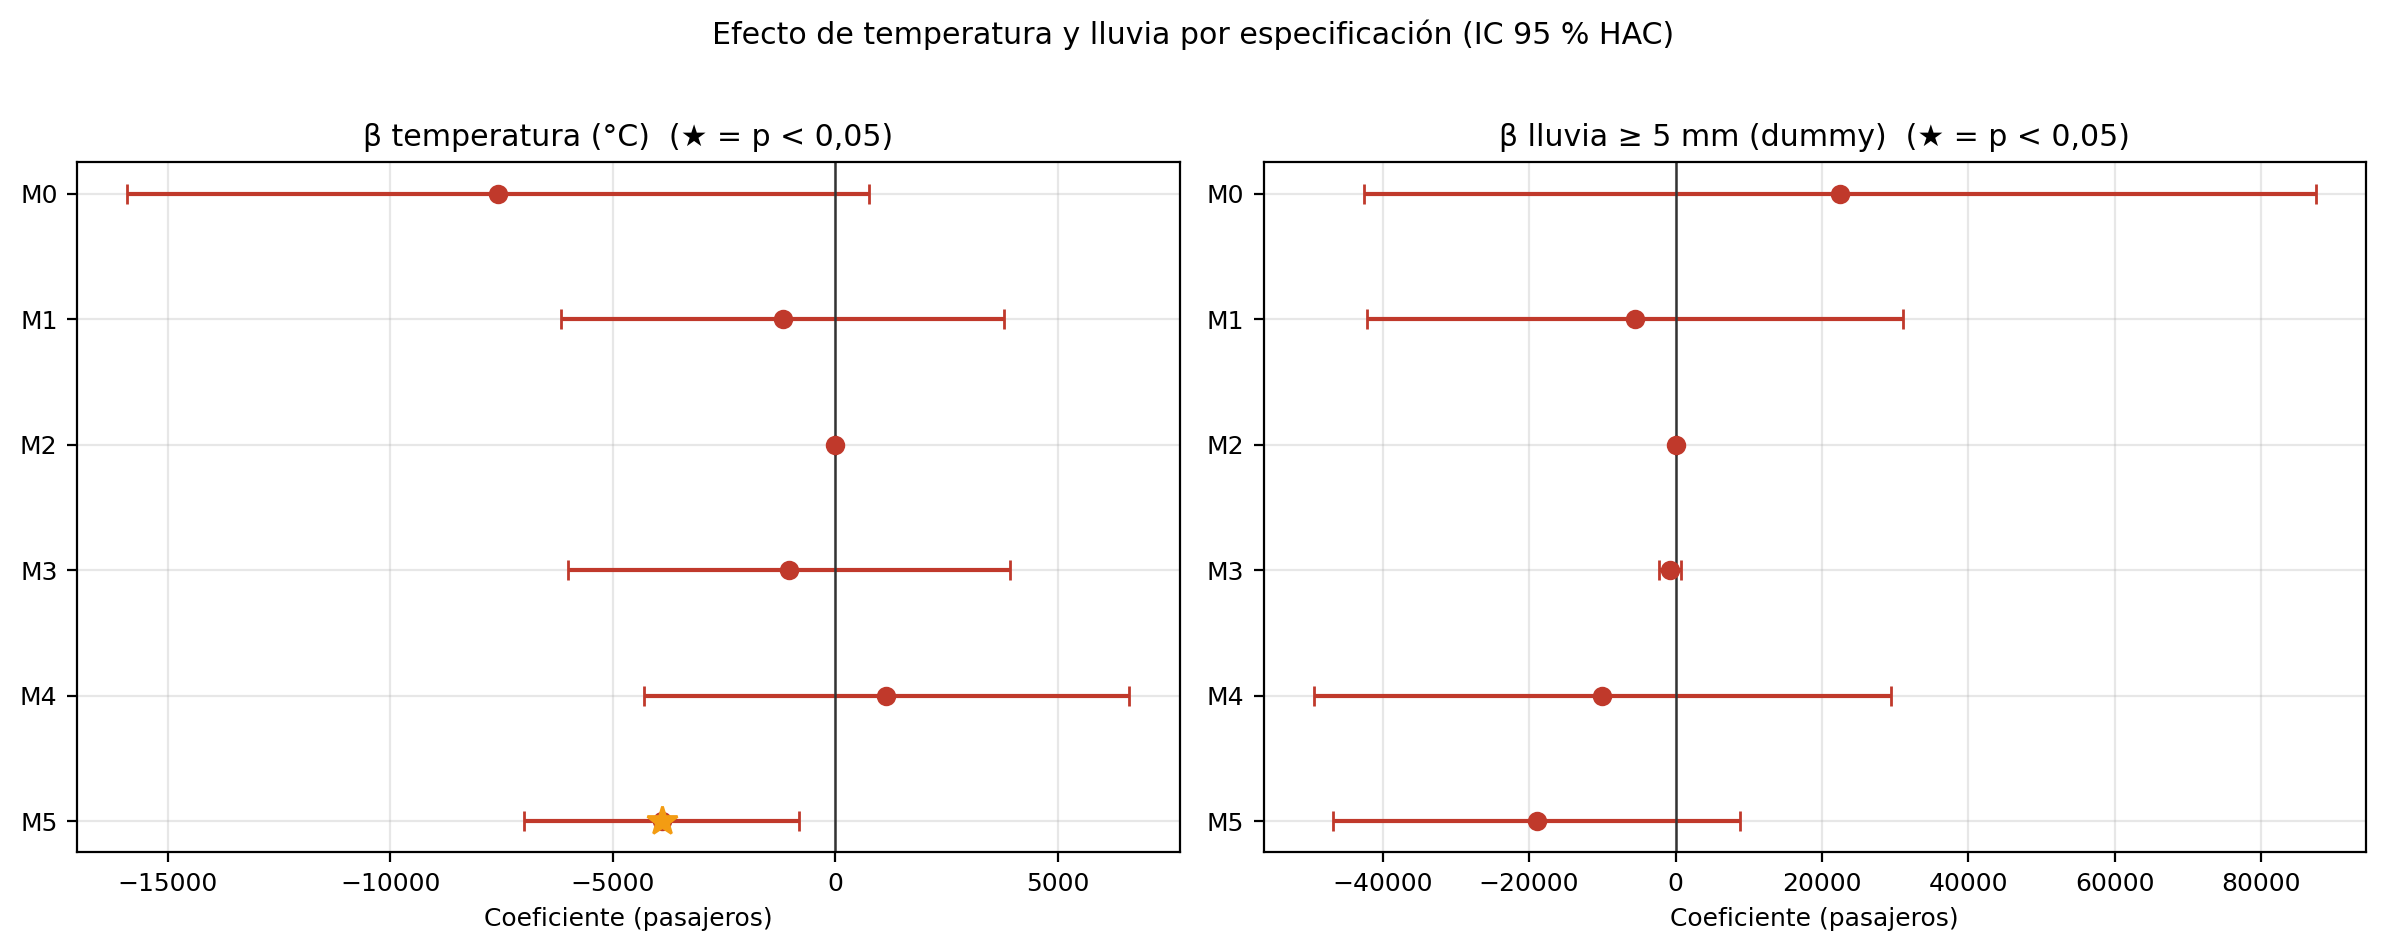

fig10_perfiles_por_cluster.png


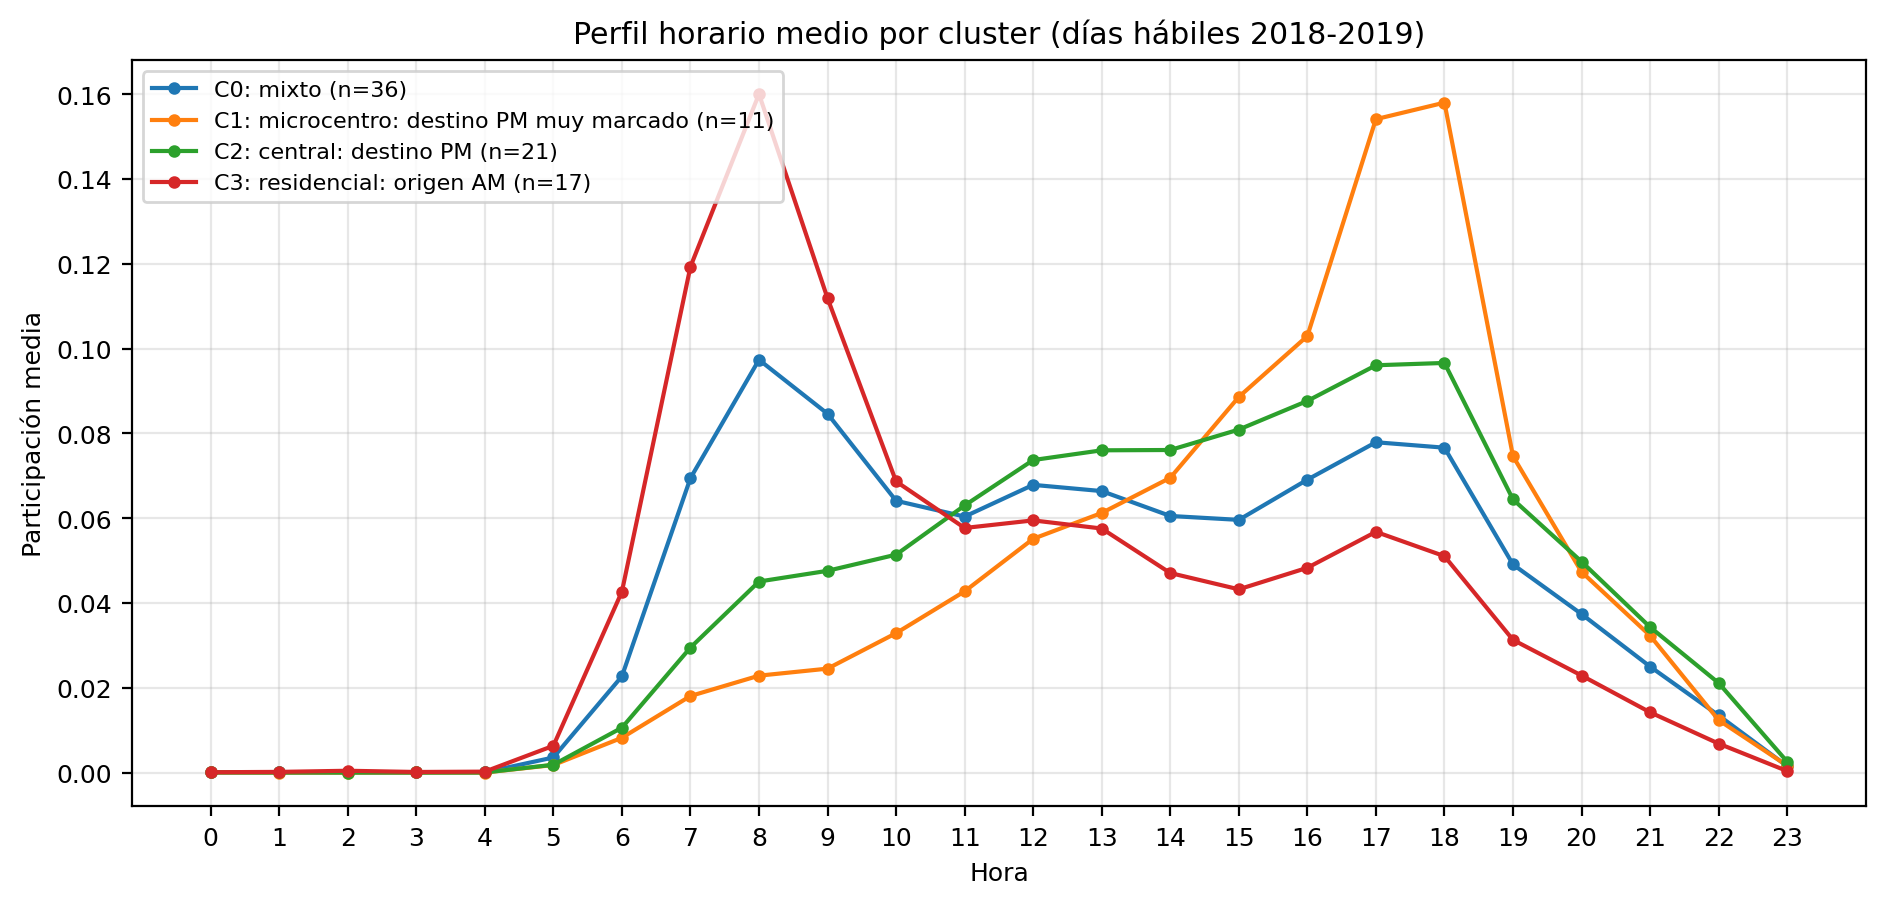

fig12_real_vs_predicho_rmse.png


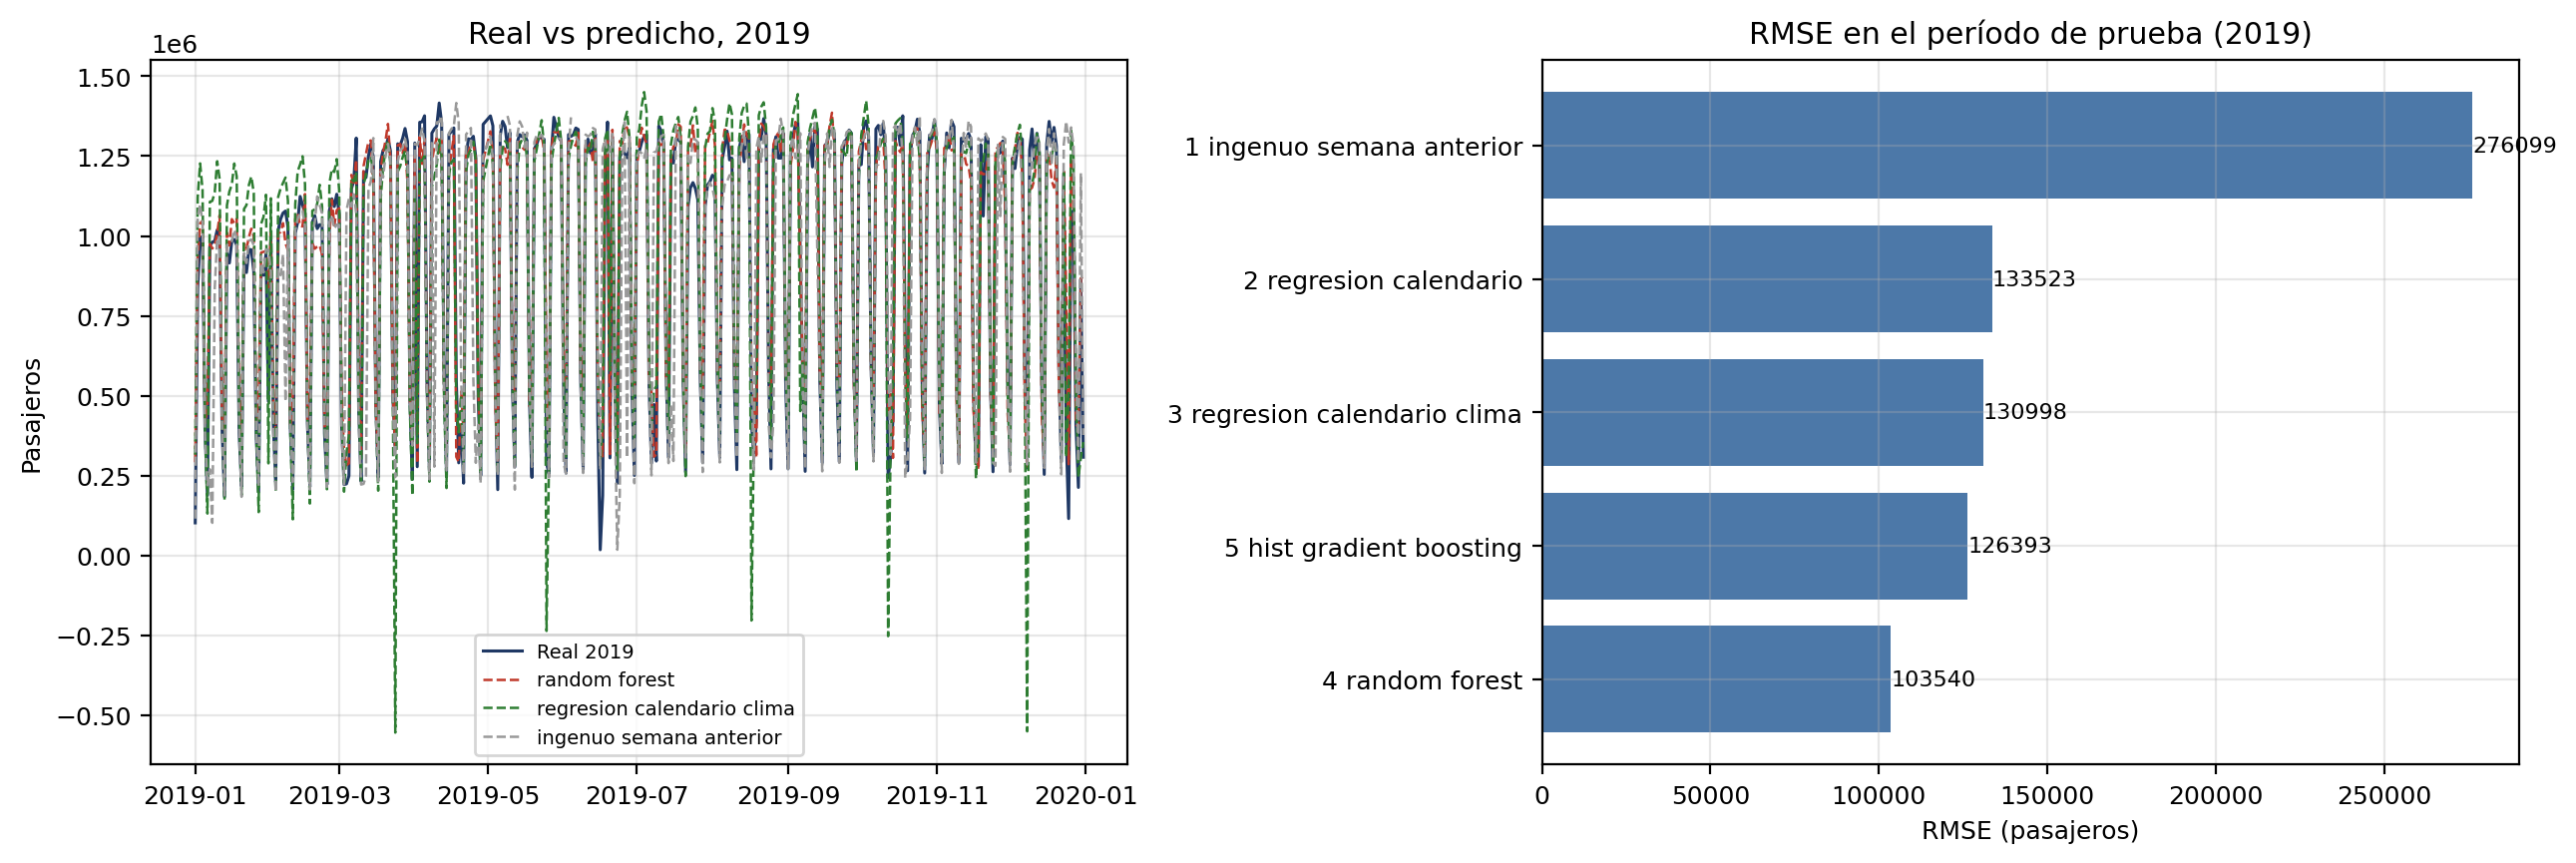

In [7]:
# 7. Figuras principales
from IPython.display import Image, display
F = "Ultima entrega/resultados/figuras/"
for f in ["fig01_serie_diaria_fases_atipicos.png", "fig05_boxplots_h2.png",
          "fig06_forest_plot_especificaciones.png", "fig10_perfiles_por_cluster.png",
          "fig12_real_vs_predicho_rmse.png"]:
    print(f); display(Image(F + f, width=900))